## FSHD test: case ONT022

In [ ]:
##### Basic information #####
PREFIX="ONT022"

In [2]:
### Importing modules ###
import os
import multiprocessing
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### DIRECTORIES ###
TMP = "/raid/tmp/fshd"
QUERY = "/lab_nas_home_user/Mark/FSHD/querySeq"

### Resources ###
cores = int(multiprocessing.cpu_count() * 0.75)

### Softwares ###
BLASTN = "/Everythings/misc/ncbi-blast-2.13.0+/bin/blastn"
MAKEBLASTDB = "/Everythings/misc/ncbi-blast-2.13.0+/bin/makeblastdb"
MODKIT = "/Everythings/misc/modkit_v0.2.4/modkit"

In [3]:
### Path to BAM file ###
directory="/nanopore_nas/nanopore_pipeline"
matching_folder = next(folder for folder in os.listdir(directory) if PREFIX in folder)
BAM = os.path.join(directory, matching_folder, matching_folder+".bam")

In [18]:
### Prettify the output ###
blast_title = ['QuerySeq-id', 'Seq-id', 'Identity%', 'Alignment-length', 'Mismatches', 'Gap', 'Q.Start', 'Q.End', 'S.Start', 'S.End', 'E-value', 'Bit-score']

In [4]:
### Create fasta file from BAM file, extract reads mapped to chr4 ###
os.system("samtools view -b "+BAM+" chr4 | samtools fasta - > "+TMP+"/"+PREFIX+"_chr4.fasta")

[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 675338 reads


0

In [5]:
### Create BLAST database ###
os.system(MAKEBLASTDB+" -in "+TMP+"/"+PREFIX+"_chr4.fasta -dbtype nucl -out "+TMP+"/blastdb/chr4 -title "+PREFIX)



Building a new DB, current time: 12/12/2024 13:42:52
New DB name:   /raid/tmp/fshd/blastdb/chr4
New DB title:  ONT022
Sequence type: Nucleotide
Keep MBits: T
Maximum file size: 3000000000B
Adding sequences from FASTA; added 675338 sequences in 33.7322 seconds.




0

Get sequence ID with tail sequence (pLAM)

In [ ]:
### Find reads have tail sequence (pLAM) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/pLAM.fasta -out "+TMP+"/"+PREFIX+"_pLAM.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
pLAM_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_pLAM.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)
pLAM_blast.head()

,Seq-id,Identity%,Alignment-length,Mismatches,Gap,Q.Start,Q.End,S.Start,S.End,E-value,Bit-score
1,e259ae35-98d2-4f18-922c-1580961f558a,84.375,192,28,2,1,191,2505,2695,3.710000e-45,187
0,7661d166-2119-4d52-8742-29a068049e2c,83.582,201,32,1,1,200,5079,5279,3.710000e-45,187
2,7c6d052b-0550-4716-9f13-a14ded19fddf,83.168,202,32,2,1,200,5529,5730,4.790000e-44,183
3,d4da5c2b-907e-4332-ad5f-f82176a66438,81.463,205,33,2,1,200,52098,51894,6.240000e-38,163


Get sequence ID with head sequence (P13E11)

In [29]:
### Find reads have head sequence (P13E11) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/P13E11.fasta -out "+TMP+"/"+PREFIX+"_P13E11.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
P13E11_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_P13E11.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)
P13E11_blast.head()

,Seq-id,Identity%,Alignment-length,Mismatches,Gap,Q.Start,Q.End,S.Start,S.End,E-value,Bit-score
0,e1aadba1-b8bc-4270-bb65-c5535fd623c9,100.0,220,0,0,1,220,16023,15804,2.920000e-111,407
1,57792f8d-c69a-434d-a7f1-c1b10555565d,100.0,220,0,0,1,220,827,608,2.920000e-111,407
2,84911b61-8d1d-487f-ba3d-7e54aa3f0ba7,100.0,220,0,0,1,220,12949,13168,2.920000e-111,407
3,41f13b02-601e-4302-be46-50dd853b5d0d,100.0,220,0,0,1,220,23042,23261,2.920000e-111,407
4,55243ec8-73ce-4a6c-8fdb-f2f11fa37b96,100.0,220,0,0,1,220,27901,28120,2.920000e-111,407


Count D4Z4 repeat units

In [38]:
### Find reads have D4Z4 ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/MIR8078.fasta -out "+TMP+"/"+PREFIX+"_D4Z4.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
D4Z4_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_D4Z4.blast", header=None, sep="\t", names=blast_title)
        .drop(columns=['QuerySeq-id'])
        .sort_values(by='Identity%', ascending=False)
)

# Count number of reads, grouped by Seq-id
D4Z4_count = D4Z4_blast.groupby('Seq-id').size().reset_index(name='Count').sort_values(by='Count', ascending=False)

Count D4Z4 repeats having **EITHER head OR tail**

In [39]:
# Find unique sequences from the first column of both pLAM_blast and P13E11_blast
unique_sequences = set(pLAM_blast['Seq-id']).union(set(P13E11_blast['Seq-id']))

if len(unique_sequences) == 0:
    print("No unique sequences found.")
else:
    # Extract rows from D4Z4_count where Seq-id is in unique_sequences
    count_head_or_tail = D4Z4_count[D4Z4_count['Seq-id'].isin(unique_sequences)]
    count_head_or_tail.head()

,Seq-id,Count
111,ba8b14f4-2eb2-4bf7-ae92-7d8b3d584e35,15
56,55243ec8-73ce-4a6c-8fdb-f2f11fa37b96,11
49,4a374181-574c-4dbf-a8e4-65342191b2be,11
153,ff02fc10-b72b-4904-8d03-4b7e41e5470d,10
42,41190030-ccdd-420d-8a65-872ec9cff812,8


Count D4Z4 repeats having **BOTH head AND tail**

In [42]:
# Find sequences from the first column in both pLAM_blast and P13E11_blast
common_sequences = set(pLAM_blast['Seq-id']).intersection(set(P13E11_blast['Seq-id']))

if len(common_sequences) == 0:
    print("No common sequences found.")
else: 
    # Extract rows from D4Z4_count where Seq-id is in common_sequences
    count_head_and_tail = D4Z4_count[D4Z4_count['Seq-id'].isin(common_sequences)]
    count_head_and_tail.head()

No common sequences found.


Check polyA tail

In [66]:
### Find reads have tail sequence (pLAM) ###
os.system(BLASTN+" -db "+TMP+"/blastdb/chr4 -query "+QUERY+"/pLAM-polyA.fasta -out "+TMP+"/"+PREFIX+"_pLAM_polyA.blast -num_threads "+str(cores)+" -outfmt 6")

# Load result
pLAM_polyA_blast = (
    pd.read_table(TMP+"/"+PREFIX+"_pLAM_polyA.blast", header=None, sep="\t", names=blast_title)
        .sort_values(by='Identity%', ascending=False)
)

# Pivot the dataframe to have hapA and hapB mismatches in separate columns
pivot_df = pLAM_polyA_blast.pivot(index='Seq-id', columns='QuerySeq-id', values='Mismatches')
pivot_df.rename(columns={'hapA': 'hapA.Mismatches', 'hapB': 'hapB.Mismatches'}, inplace=True)

# Calculate the difference in mismatches between hapA and hapB
pivot_df['delta.Mismatches'] =  pivot_df['hapB.Mismatches'] - pivot_df['hapA.Mismatches']

# Permissive column to indicate if the sequence is hapA, hapB, or unknown
pivot_df['Permissive'] = pivot_df['delta.Mismatches'].apply(lambda x: 'hapA' if x == 1 else 'hapB' if x == -1 else 'Unknown')

# Reset the index to make 'Seq-id' a column again
result_df = pivot_df.reset_index()
result_df.columns.name = None

# Display the result
result_df.head()

,Seq-id,hapA.Mismatches,hapB.Mismatches,delta.Mismatches,Permissive
0,7661d166-2119-4d52-8742-29a068049e2c,32,31,-1,hapB
1,7c6d052b-0550-4716-9f13-a14ded19fddf,32,31,-1,hapB
2,d4da5c2b-907e-4332-ad5f-f82176a66438,33,32,-1,hapB
3,e259ae35-98d2-4f18-922c-1580961f558a,28,27,-1,hapB


Calculate methylation level

In [75]:
### Extract reads with tail by sequence ID from pLAM_blast ###
pLAM_blast['Seq-id'].to_csv(TMP + "/" + PREFIX + "_tail_ids.txt", index=False, header=False)
os.system("samtools view -b -@ "+str(cores)+" --qname-file "+TMP+"/"+PREFIX+"_tail_ids.txt "+BAM+" > "+TMP+"/"+PREFIX+"_tail.bam")
os.system("samtools index "+TMP+"/"+PREFIX+"_tail.bam")
os.system("rsync -a "+TMP+"/"+PREFIX+"_tail.bam* /lab_nas_home_user/Mark/FSHD/tail_bams/")

### Extract CpG methylation information ###
os.system(MODKIT+" pileup "+TMP+"/"+PREFIX+"_tail.bam "+TMP+"/"+PREFIX+"_CpG.txt --cpg --ignore h --combine-strands --ref /lab_nas_home_user/Mark/reference_genome/hg38/genome.fasta")

0

In [95]:
cpg_title=["chrom", "start", "end", "score", "N_validCov", "N_mod", "FracMod"]
cpg = pd.read_table(TMP+"/"+PREFIX+"_CpG.txt", header=None, sep="\s+").iloc[:, [0, 1, 2, 4, 9, 11, 10]]
cpg.columns = cpg_title
cpg.head()

,chrom,start,end,score,N_validCov,N_mod,FracMod
0,chr4,168863605,168863606,1,1,1,100.0
1,chr4,168863798,168863799,1,1,1,100.0
2,chr4,168863941,168863942,1,1,1,100.0
3,chr4,168864171,168864172,1,1,1,100.0
4,chr4,168864314,168864315,1,1,1,100.0


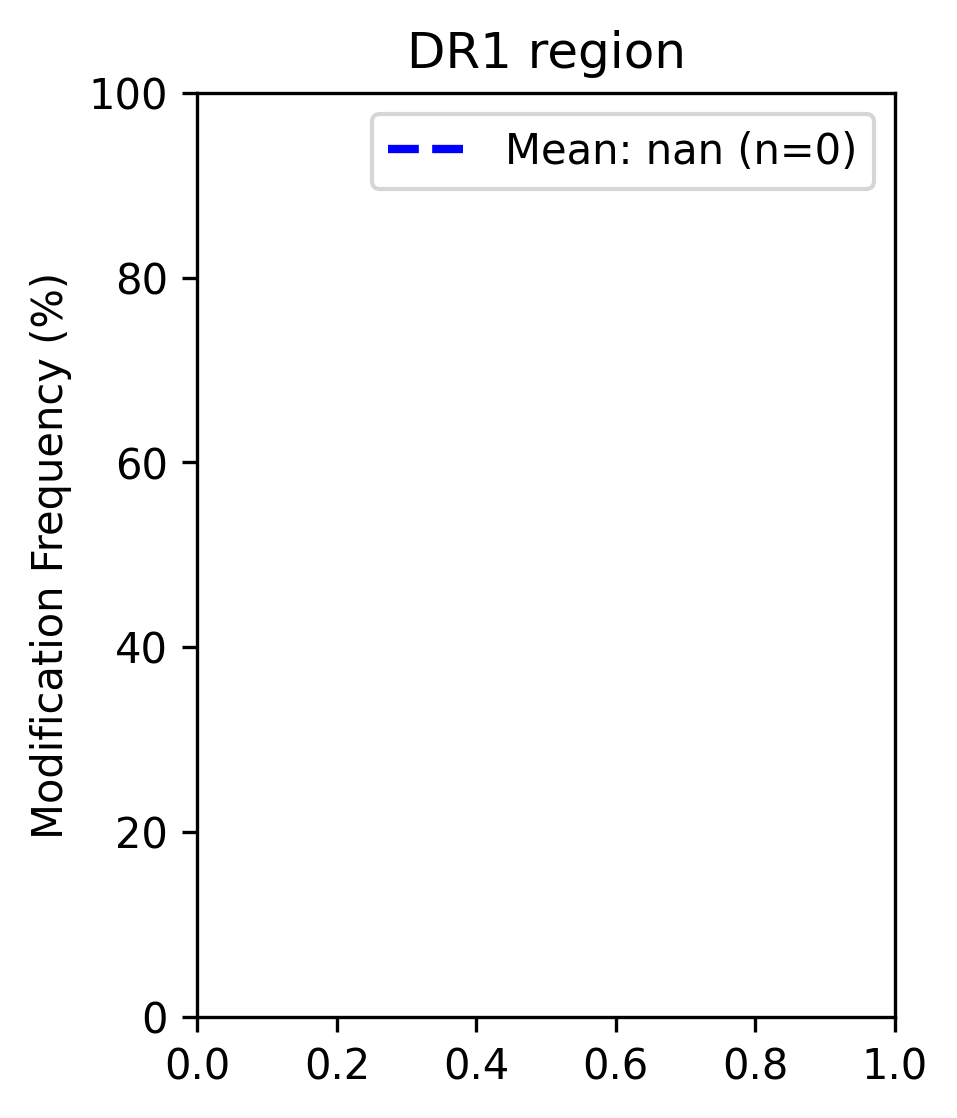

In [124]:
# DR1 region (hg38, chr4:190086470-190086723)
dr1_region = cpg[(cpg['chrom'] == 'chr4') & (cpg['start'] >= 190086470) & (cpg['end'] <= 190086723)]

# Remove rows where N_validCov is equal to 1
dr1_region_filtered = dr1_region[dr1_region['N_validCov'] != 1]

plt.figure(figsize=(3, 4), dpi=150)
sns.boxplot(y='FracMod', data=dr1_region_filtered, orient='v')
plt.title('DR1 region')
plt.ylabel('Modification Frequency (%)')
plt.ylim(0, 100)  # Set y-axis range from 0 to 100

# Calculate the mean value of FracMod
mean_fracmod_dr1 = dr1_region_filtered['FracMod'].mean()

# Add a red horizontal line at the mean value
plt.axhline(mean_fracmod_dr1, color='blue', linestyle='--', linewidth=2, label=f'Mean: {mean_fracmod_dr1:.2f} (n={len(dr1_region_filtered)})')
plt.legend()

plt.show()


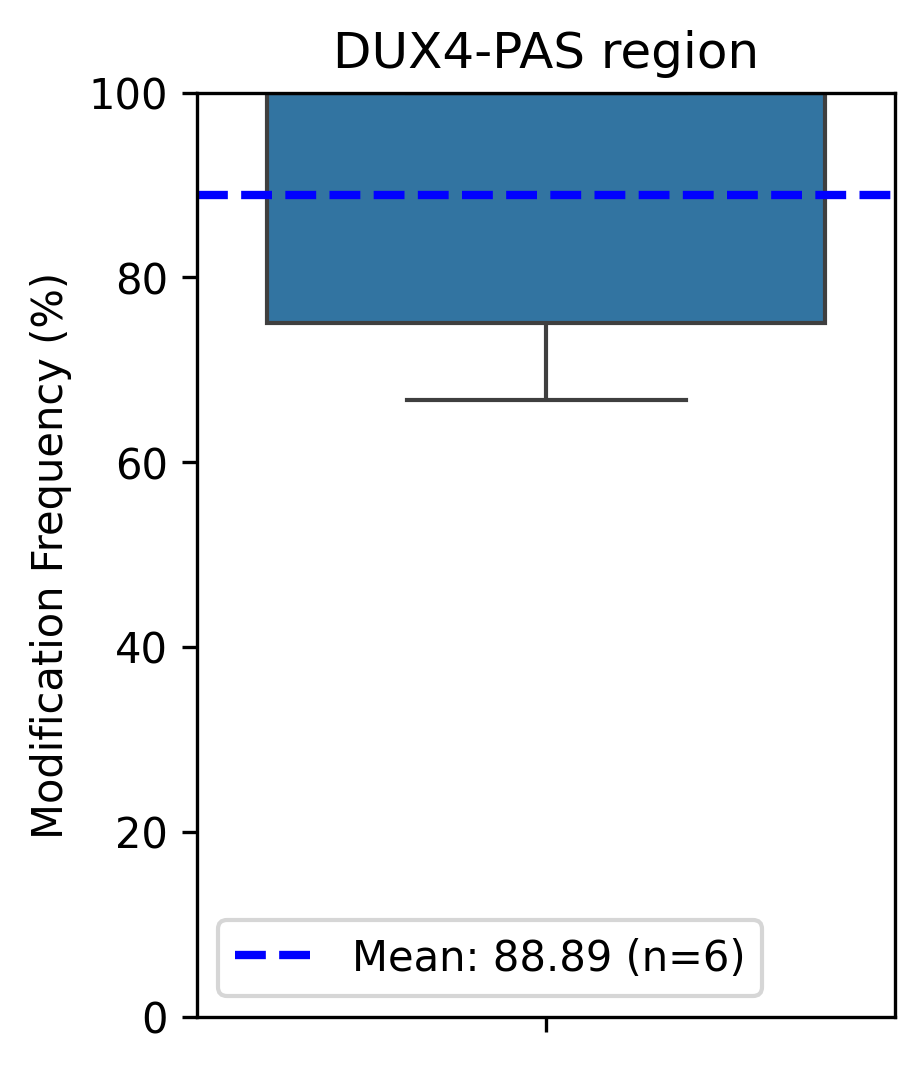

In [126]:
# DUX4-PAS region (hg38, chr4:190175600-190175834)
dux4pas = cpg[(cpg['chrom'] == 'chr4') & (cpg['start'] >= 190175600) & (cpg['end'] <= 190175834)]

# Remove rows where N_validCov is equal to 1
dux4pas_filtered = dux4pas[dux4pas['N_validCov'] != 1]

plt.figure(figsize=(3, 4), dpi=150)
sns.boxplot(y='FracMod', data=dux4pas_filtered, orient='v')
plt.title('DUX4-PAS region')
plt.ylabel('Modification Frequency (%)')
plt.ylim(0, 100)  # Set y-axis range from 0 to 100

# Calculate the mean value of FracMod
mean_fracmod = dux4pas_filtered['FracMod'].mean()

# Add a red horizontal line at the mean value
plt.axhline(mean_fracmod, color='blue', linestyle='--', linewidth=2, label=f'Mean: {mean_fracmod:.2f} (n={len(dux4pas_filtered)})')
plt.legend()

plt.show()


In [3]:
### Remove tmp files
os.system("rm -r "+TMP+"/*")

0